# SafeStep · 6 — Robustness: noise · sampling rate · no gyroscope · phone rotation · calibration · young→elderly
Every test recording is **re-processed from raw signals** under each condition with the same pipeline the app uses.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os, sys, json, time, shutil, warnings
import numpy as np, pandas as pd, joblib
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import f1_score, confusion_matrix, average_precision_score, balanced_accuracy_score
warnings.filterwarnings('ignore')
BASE = '/content/drive/MyDrive/Daffodil Robo Tech Olympiad'
PROJ = f'{BASE}/SafeStep'
D = {k: f'{PROJ}/{k}' for k in ['data', 'artifacts', 'figures', 'models', 'code']}
DEPLOY = f"{D['models']}/deploy"; os.makedirs(DEPLOY, exist_ok=True)
sys.path.insert(0, D['code']); import safestep_core as core
SEED = 42; rng = np.random.default_rng(SEED)
sns.set_theme(style='whitegrid'); plt.rcParams['figure.dpi'] = 110
def save_fig(name): plt.savefig(f"{D['figures']}/{name}.png", dpi=300, bbox_inches='tight')
FS, W = core.FS, core.WIN
F    = pd.read_parquet(f"{D['data']}/features_345.parquet").set_index('win_id')
wm   = pd.read_parquet(f"{D['data']}/windows_meta.parquet").set_index('win_id')
meta = pd.read_parquet(f"{D['data']}/trials_meta.parquet").set_index('trial_id')
SEL  = json.load(open(f"{D['artifacts']}/feature_selection.json"))
CFG  = json.load(open(f"{DEPLOY}/deploy_config.json"))
try:
    import lightgbm as lgb
    def make_model(): return lgb.LGBMClassifier(n_estimators=400, learning_rate=0.05, num_leaves=63, subsample=0.8, subsample_freq=1,
                                                colsample_bytree=0.8, class_weight='balanced', n_jobs=-1, random_state=SEED, verbose=-1)
except ImportError:
    def make_model(): return ExtraTreesClassifier(n_estimators=400, min_samples_leaf=2, class_weight='balanced', n_jobs=-1, random_state=SEED)
print(F.shape, '| deployed fall model:', CFG['fall_model'], '| activity model:', CFG['activity_model'])

(136051, 345) | deployed fall model: MLP | activity model: LightGBM


In [3]:
class Streamer:
    """slides over whole recordings of one split, scores alarms like the live app."""
    def __init__(self, split, ages=None):
        sub = wm[wm.split == split].sort_values(['trial_id', 'start'])
        if ages: sub = sub[sub.age_group.isin(ages)]
        self.win_ids = sub.index.values
        local = {w: i for i, w in enumerate(sub.index)}
        self.trials = []
        for tid, g in sub.groupby('trial_id', sort=False):
            r = meta.loc[tid]
            self.trials.append(dict(tid=tid, rows=np.array([local[w] for w in g.index]), starts=g.start.values,
                                    t_end=(g.start.values + W) / FS, impact=r.peak_idx / FS if r.type == 'Fall' else None,
                                    type=r.type, code=r.code, age=r.age_group, hours=r.duration_s / 3600))
    @staticmethod
    def alarms(p, t_end, thr, k, refractory=10.0):
        hit = p >= thr
        if k > 1: hit = np.convolve(hit.astype(int), np.ones(k, int), 'full')[:len(hit)] >= k
        out, last = [], -1e9
        for t in t_end[hit]:
            if t - last >= refractory: out.append(t); last = t
        return out
    def evaluate(self, p, thr, k=1, ages=None):
        caught = n_fall = fa = 0; hours = 0.0; delays = []
        for tr in self.trials:
            if ages and tr['age'] not in ages: continue
            al = self.alarms(p[tr['rows']], tr['t_end'], thr, k)
            if tr['type'] == 'Fall':
                n_fall += 1; ok = [a for a in al if tr['impact'] <= a <= tr['impact'] + W / FS + 0.5]
                caught += bool(ok)
                if ok: delays.append(ok[0] - tr['impact'])
            else:
                fa += len(al); hours += tr['hours']
        return dict(sensitivity=caught / max(n_fall, 1) if n_fall else np.nan, fa_per_hour=fa / max(hours, 1e-9) if hours else np.nan,
                    false_alarms=fa, falls=n_fall, adl_hours=hours, median_delay=float(np.median(delays)) if delays else np.nan)

GRID = np.r_[np.linspace(0.05, 0.95, 19), 0.97, 0.98, 0.99]
def tune(st, p, fa_target=1.0, ks=(1, 2)):
    best = None
    for k in ks:
        for thr in GRID:
            r = st.evaluate(p, thr, k)
            key = (r['fa_per_hour'] <= fa_target, r['sensitivity'], -r['fa_per_hour'])
            if best is None or key > best[0]: best = (key, dict(thr=float(thr), k=k, **r))
    return best[1]

In [4]:
signals = np.load(f"{D['data']}/signals_50hz.npz")['signals']
fall_m = joblib.load(f"{DEPLOY}/fall_model.joblib"); act_m = joblib.load(f"{DEPLOY}/activity_model.joblib")
FEATS, THR, K = CFG['features'], CFG['threshold'], CFG['consecutive_windows']
ACT = np.array(CFG['activity_classes'])
ST = {s: Streamer(s) for s in ['val', 'test']}
te_trials = [tr['tid'] for tr in ST['test'].trials]
act_true = wm.loc[ST['test'].win_ids, 'y_activity'].values

# a device-dependent model (uses raw axis features) for the rotation comparison
dev_path = f"{D['models']}/classical/fall__sel_all__{CFG['fall_model']}.joblib"
DEV = None
if os.path.exists(dev_path):
    DEV = joblib.load(dev_path); DEV_FEATS = SEL['selected_all']
    pv = DEV.predict_proba(F.loc[ST['val'].win_ids, DEV_FEATS].values)[:, 1]
    DEV_CFG = tune(ST['val'], pv)
    print('device-feature model loaded; tuned threshold', DEV_CFG['thr'])

def rotation(deg, seed=0):
    r = np.random.default_rng(seed); ax = r.normal(size=3); ax /= np.linalg.norm(ax)
    a = np.radians(deg); Kx = np.array([[0, -ax[2], ax[1]], [ax[2], 0, -ax[0]], [-ax[1], ax[0], 0]])
    return np.eye(3) + np.sin(a) * Kx + (1 - np.cos(a)) * Kx @ Kx

def perturb(acc, gyr, kind, level, seed=0):
    r = np.random.default_rng(seed); acc, gyr = acc.copy(), gyr.copy()
    if kind == 'noise':
        acc += r.normal(0, level, acc.shape); gyr += r.normal(0, level * 100, gyr.shape)
    elif kind == 'rate':
        step = max(int(round(FS / level)), 1); t = np.arange(len(acc)); ts = t[::step]
        acc = np.column_stack([np.interp(t, ts, acc[::step, i]) for i in range(3)])
        gyr = np.column_stack([np.interp(t, ts, gyr[::step, i]) for i in range(3)])
    elif kind == 'gyro_off':
        gyr[:] = 0
    elif kind == 'rotation':
        R = rotation(level, seed); acc, gyr = acc @ R.T, gyr @ R.T
    elif kind == 'scale':
        acc *= level; gyr *= level
    return acc, gyr

def features_under(kind, level):
    """recompute all 345 features of every test window under one condition (same row order as the Streamer)."""
    out = np.zeros((len(ST['test'].win_ids), len(core.FEATURE_NAMES)), np.float32)
    for n, tr in enumerate(ST['test'].trials):
        r = meta.loc[tr['tid']]; x = signals[r.offset:r.offset + r.n_samples].astype(np.float64)
        a, g = perturb(x[:, 0:3], x[:, 3:6], kind, level, seed=int(tr['tid']))
        out[tr['rows']] = core.extract_features(core.trial_windows(a, g, tr['starts']))
    return pd.DataFrame(out, columns=core.FEATURE_NAMES)

def score(X, model, feats, thr, k, name):
    p = model.predict_proba(X[feats].values)[:, 1]
    r = ST['test'].evaluate(p, thr, k)
    m = act_true != 'ignore'
    f1 = f1_score(act_true[m], ACT[act_m.predict_proba(X.loc[m, FEATS].values).argmax(1)], average='macro') if name == 'SafeStep (phone-ready)' else np.nan
    return dict(model=name, sensitivity=r['sensitivity'], fa_per_hour=r['fa_per_hour'], act_f1=f1)
print(len(te_trials), 'test recordings')

device-feature model loaded; tuned threshold 0.95
1163 test recordings


In [5]:
PLAN = [('noise', [0.0, 0.01, 0.02, 0.05, 0.1]), ('rate', [50, 25, 20, 10]), ('gyro_off', [1]),
        ('rotation', [0, 30, 60, 90, 180]), ('scale', [0.8, 0.9, 1.0, 1.1, 1.2])]
CACHE = f"{D['artifacts']}/robustness.csv"
rows = pd.read_csv(CACHE).to_dict('records') if os.path.exists(CACHE) else []
done = {(r['perturbation'], float(r['level'])) for r in rows}
for kind, levels in PLAN:
    for lv in levels:
        if (kind, float(lv)) in done: continue
        t0 = time.time(); X = features_under(kind, lv)
        rr = [score(X, fall_m, FEATS, THR, K, 'SafeStep (phone-ready)')]
        if kind == 'rotation' and DEV is not None:
            rr.append(score(X, DEV, DEV_FEATS, DEV_CFG['thr'], DEV_CFG['k'], 'device-axis features'))
        for r in rr:
            rows.append(dict(perturbation=kind, level=lv, **r))
            print(f"{kind:8s} {lv:6} {r['model']:24s} caught {r['sensitivity']:.3f} | FA/h {r['fa_per_hour']:.2f} | act F1 {r['act_f1']:.3f}  ({time.time()-t0:.0f}s)")
        pd.DataFrame(rows).to_csv(CACHE, index=False)
RB = pd.DataFrame(rows)

noise       0.0 SafeStep (phone-ready)   caught 0.962 | FA/h 0.00 | act F1 0.888  (66s)
noise      0.01 SafeStep (phone-ready)   caught 0.962 | FA/h 0.00 | act F1 0.843  (63s)
noise      0.02 SafeStep (phone-ready)   caught 0.958 | FA/h 0.00 | act F1 0.817  (66s)
noise      0.05 SafeStep (phone-ready)   caught 0.964 | FA/h 0.00 | act F1 0.729  (64s)
noise       0.1 SafeStep (phone-ready)   caught 0.969 | FA/h 0.26 | act F1 0.566  (64s)
rate         50 SafeStep (phone-ready)   caught 0.962 | FA/h 0.00 | act F1 0.888  (66s)
rate         25 SafeStep (phone-ready)   caught 0.956 | FA/h 0.00 | act F1 0.866  (64s)
rate         20 SafeStep (phone-ready)   caught 0.956 | FA/h 0.00 | act F1 0.866  (63s)
rate         10 SafeStep (phone-ready)   caught 0.758 | FA/h 0.79 | act F1 0.699  (63s)
gyro_off      1 SafeStep (phone-ready)   caught 0.840 | FA/h 0.00 | act F1 0.766  (63s)
rotation      0 SafeStep (phone-ready)   caught 0.962 | FA/h 0.00 | act F1 0.888  (64s)
rotation      0 device-axis feat

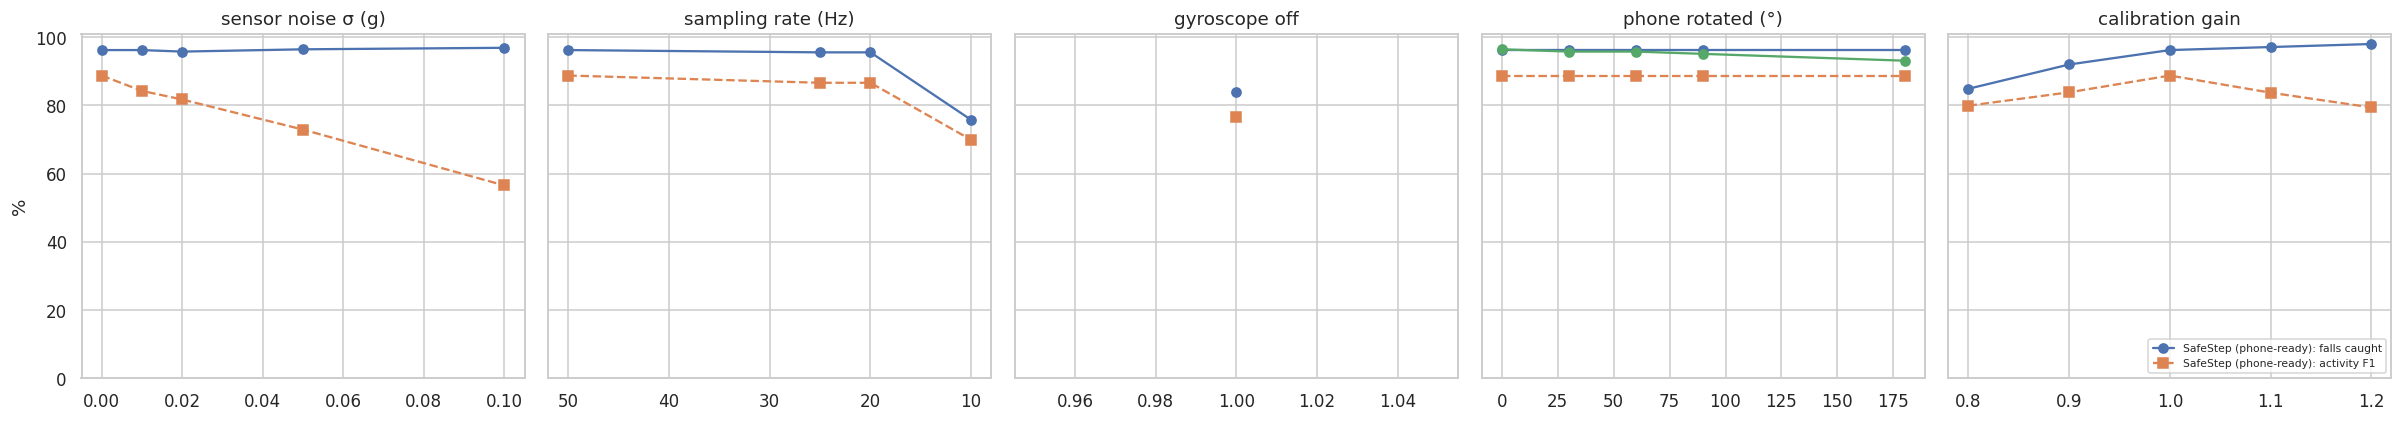

fa_per_hour                       \
model               SafeStep (phone-ready) device-axis features   
perturbation level                                                
gyro_off     1.00                    0.000                  NaN   
noise        0.00                    0.000                  NaN   
             0.01                    0.000                  NaN   
             0.02                    0.000                  NaN   
             0.05                    0.000                  NaN   
             0.10                    0.262                  NaN   
rate         10.00                   0.787                  NaN   
             20.00                   0.000                  NaN   
             25.00                   0.000                  NaN   
             50.00                   0.000                  NaN   
rotation     0.00                    0.000                0.262   
             30.00                   0.000                0.787   
             60.00                   0.000                2.884   
             90.00                   0.000               12.586   
             180.00                  0.000               22.812   
scale        0.80                    0.000                  NaN   
             0.90                    0.000                  NaN   
             1.00                    0.000                  NaN   
             1.10                    0.787                  NaN   
             1.20                    1.835                  NaN   

                               sensitivity                       
model               SafeStep (phone-ready) device-axis features  
perturbation level                                               
gyro_off     1.00                    0.840                  NaN  
noise        0.00                    0.962                  NaN  
             0.01                    0.962                  NaN  
             0.02                    0.958                  NaN  
             0.05                    0.964                  NaN  
             0.10                    0.969                  NaN  
rate         10.00                   0.758                  NaN  
             20.00                   0.956                  NaN  
             25.00                   0.956                  NaN  
             50.00                   0.962                  NaN  
rotation     0.00                    0.962                0.964  
             30.00                   0.962                0.958  
             60.00                   0.962                0.958  
             90.00                   0.962                0.951  
             180.00                  0.962                0.931  
scale        0.80                    0.849                  NaN  
             0.90                    0.920                  NaN  
             1.00                    0.962                  NaN  
             1.10                    0.971                  NaN  
             1.20                    0.980                  NaN

In [6]:
fig, axes = plt.subplots(1, 5, figsize=(22, 4), sharey=True)
titles = {'noise': 'sensor noise σ (g)', 'rate': 'sampling rate (Hz)', 'gyro_off': 'gyroscope off', 'rotation': 'phone rotated (°)', 'scale': 'calibration gain'}
for ax, (kind, _) in zip(axes, PLAN):
    d = RB[RB.perturbation == kind]
    for mdl, g in d.groupby('model'):
        ax.plot(g.level, g.sensitivity * 100, 'o-', label=f'{mdl}: falls caught')
        if g.act_f1.notna().any(): ax.plot(g.level, g.act_f1 * 100, 's--', label=f'{mdl}: activity F1')
    ax.set_title(titles[kind]); ax.set_ylim(0, 101)
    if kind == 'rate': ax.invert_xaxis()
axes[0].set_ylabel('%'); axes[-1].legend(fontsize=7, loc='lower right')
plt.tight_layout(); save_fig('60_robustness'); plt.show()
RB.pivot_table(index=['perturbation', 'level'], columns='model', values=['sensitivity', 'fa_per_hour']).round(3)

## Young → elderly: what if the model never sees elderly movement?

In [7]:
from sklearn.base import clone
young_tr = np.where(((wm.split == 'train') & (wm.age_group == 'young')).values)[0]
t_end = wm.t_end_rel_impact.values
y_fall = np.select([wm.phase == 'impact', wm.phase == 'adl', (wm.phase == 'pre_fall') & (t_end < -1.0),
                    (wm.phase == 'post_fall') & (t_end > W / FS + 1.0)], [1, 0, 0, 0], -1)
young_tr = young_tr[y_fall[young_tr] >= 0]
cap = min(len(young_tr), 60000); young_tr = rng.choice(young_tr, cap, replace=False)
yo = clone(fall_m).fit(F[FEATS].values[young_tr], y_fall[young_tr])
st_val_y = Streamer('val', ages=['young'])
cfg_y = tune(st_val_y, yo.predict_proba(F.loc[st_val_y.win_ids, FEATS].values)[:, 1])
ca = []
for name, mdl, thr, k in [('young + elderly (SafeStep)', fall_m, THR, K), ('young only', yo, cfg_y['thr'], cfg_y['k'])]:
    p = mdl.predict_proba(F.loc[ST['test'].win_ids, FEATS].values)[:, 1]
    for age in ['young', 'elderly']:
        r = ST['test'].evaluate(p, thr, k, ages=[age])
        ca += [dict(training=name, metric=f'falls caught · {age}', value=r['sensitivity']),
               dict(training=name, metric=f'false alarms/h · {age}', value=r['fa_per_hour'])]
CA = pd.DataFrame(ca); CA.to_csv(f"{D['artifacts']}/cross_age.csv", index=False)
CA.pivot(index='metric', columns='training', values='value').round(3)

training,young + elderly (SafeStep),young only
metric,,
falls caught · elderly,0.867,0.827
falls caught · young,0.981,0.989
false alarms/h · elderly,0.000,0.000
false alarms/h · young,0.000,0.000


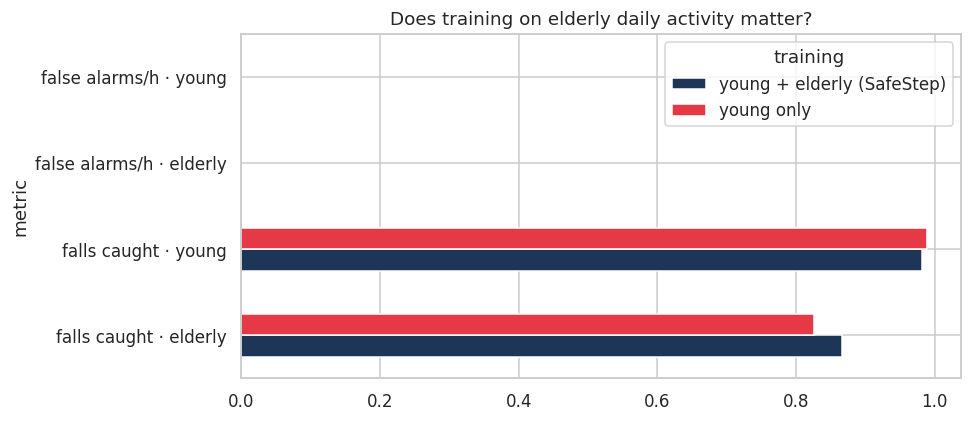

In [8]:
p = CA.pivot(index='metric', columns='training', values='value')
p.plot.barh(figsize=(9, 4), color=['#1d3557', '#e63946']); plt.title('Does training on elderly daily activity matter?')
plt.tight_layout(); save_fig('61_cross_age'); plt.show()